## Traditional Machine Learning

HOG, LBP and image statistics for PAI 3, 4 and 5 classification.


In [1]:
from pathlib import Path
from PIL import Image
from skimage.feature import hog, local_binary_pattern
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#Set the path to the cropped lesion images
DATA_DIR = Path("../dataset/lesion_crops")

#Define the lesion classes
CLASSES = [3, 4, 5]

#Check that the dataset exists
print("Dataset found:", DATA_DIR.exists())


Dataset found: True


## Feature Extraction

Convert each lesion crop into numerical features.


In [15]:
#Extract numerical features from one image
def extract_features(image_path):

    #Load the image in grayscale
    image = Image.open(image_path).convert("L")

    #Resize to reduce processing time
    image = image.resize((64, 64))

    #Convert image to a NumPy array
    pixels = np.array(image)

    #Extract edge and shape features using HOG
    hog_features = hog(
        pixels,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2)
    )

    #Extract texture patterns using LBP
    lbp = local_binary_pattern(
        pixels, P=8, R=1, method="uniform"
    )

    #Create a normalized LBP histogram
    lbp_hist, _ = np.histogram(
        lbp, bins=10, range=(0, 10)
    )
    lbp_hist = lbp_hist.astype(float)
    lbp_hist /= lbp_hist.sum() + 1e-8

    #Calculate basic image statistics
    statistics = [
        pixels.mean(),
        pixels.std(),
        np.median(pixels)
    ]

    #Combine all features into one vector
    return np.concatenate([
        hog_features,
        lbp_hist,
        statistics
    ])


## Load Dataset

Use the existing training, validation and test splits.


In [16]:
#Load images and extract features for one dataset split
def load_dataset(split):

    features = []
    labels = []

    for label in CLASSES:

        folder = DATA_DIR / split / str(label)
        image_files = sorted(folder.glob("*.jpg"))

        print(f"{split} - PAI {label}: {len(image_files)} images")

        for image_path in image_files:

            #Extract features from the current lesion
            feature_vector = extract_features(image_path)

            features.append(feature_vector)
            labels.append(label)

    return np.array(features), np.array(labels)


#Prepare training, validation and test datasets
X_train, y_train = load_dataset("train")
X_val, y_val = load_dataset("validation")
X_test, y_test = load_dataset("test")

print("\nDataset shapes:")
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)


train - PAI 3: 2904 images
train - PAI 4: 1193 images
train - PAI 5: 476 images
validation - PAI 3: 666 images
validation - PAI 4: 274 images
validation - PAI 5: 118 images
test - PAI 3: 628 images
test - PAI 4: 269 images
test - PAI 5: 103 images

Dataset shapes:
Training: (4573, 1777)
Validation: (1058, 1777)
Test: (1000, 1777)


## Logistic Regression

Train and evaluate the baseline classifier.


Logistic Regression - Validation Results
              precision    recall  f1-score   support

           3       0.83      0.81      0.82       666
           4       0.48      0.51      0.50       274
           5       0.67      0.62      0.64       118

    accuracy                           0.71      1058
   macro avg       0.66      0.65      0.65      1058
weighted avg       0.72      0.71      0.72      1058



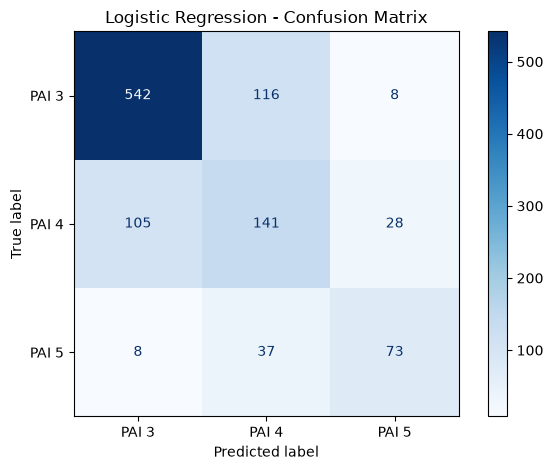

In [17]:
#Create a model with feature scaling
model_lr = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    )
)

#Train the model using training data
model_lr.fit(X_train, y_train)

#Evaluate on validation data
y_pred = model_lr.predict(X_val)

print("Logistic Regression - Validation Results")
print(classification_report(y_val, y_pred, zero_division=0))

#Display the confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred,
    labels=CLASSES,
    display_labels=["PAI 3", "PAI 4", "PAI 5"],
    cmap="Blues"
)

plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()


## Save Logistic Regression

Store the model and validation metrics.


In [18]:
from sklearn.metrics import accuracy_score, f1_score
import joblib

#Create folders for models and results
MODELS_DIR = Path("../models")
RESULTS_DIR = Path("../results")

MODELS_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

#Calculate validation metrics
lr_accuracy = accuracy_score(y_val, y_pred)
lr_f1 = f1_score(y_val, y_pred, average="macro")

#Save the trained model
joblib.dump(model_lr, MODELS_DIR / "logistic_regression.pkl")

#Save metrics for future model comparison
lr_results = pd.DataFrame([{
    "Model": "Logistic Regression",
    "Accuracy": lr_accuracy,
    "Macro F1": lr_f1
}])

lr_results.to_csv(
    RESULTS_DIR / "traditional_ml_results.csv",
    index=False
)

print("Model saved")
print(lr_results)


Model saved
                 Model  Accuracy  Macro F1
0  Logistic Regression  0.714556  0.653414


## Support Vector Machine

Train and evaluate an SVM with an RBF kernel.


SVM - Validation Results
              precision    recall  f1-score   support

           3       0.86      0.84      0.85       666
           4       0.54      0.64      0.59       274
           5       0.79      0.58      0.67       118

    accuracy                           0.76      1058
   macro avg       0.73      0.69      0.70      1058
weighted avg       0.77      0.76      0.76      1058



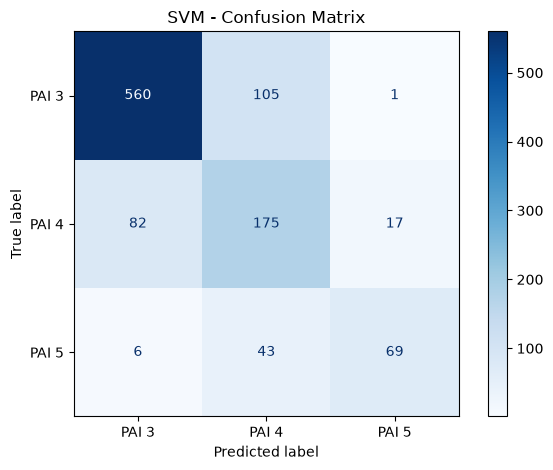

In [19]:
from sklearn.svm import SVC

#Create SVM model with feature scaling
model_svm = make_pipeline(
    StandardScaler(),
    SVC(
        kernel="rbf",
        C=1.0,
        class_weight="balanced",
        random_state=42
    )
)

#Train the SVM model
model_svm.fit(X_train, y_train)

#Evaluate using validation data
y_pred_svm = model_svm.predict(X_val)

print("SVM - Validation Results")
print(classification_report(y_val, y_pred_svm, zero_division=0))

#Display confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_svm,
    labels=CLASSES,
    display_labels=["PAI 3", "PAI 4", "PAI 5"],
    cmap="Blues"
)

plt.title("SVM - Confusion Matrix")
plt.tight_layout()
plt.show()


## Save SVM

Add SVM results to the comparison file.


In [20]:
from sklearn.metrics import accuracy_score, f1_score
import joblib

#Save the trained SVM model
joblib.dump(model_svm, MODELS_DIR / "svm_model.pkl")

#Calculate validation metrics
svm_accuracy = accuracy_score(y_val, y_pred_svm)
svm_f1 = f1_score(y_val, y_pred_svm, average="macro")

#Load the existing comparison table
results_path = RESULTS_DIR / "traditional_ml_results.csv"
results = pd.read_csv(results_path)

#Remove previous SVM results to avoid duplicates
results = results[results["Model"] != "SVM"]

#Add the new SVM results
results = pd.concat([results, pd.DataFrame([["SVM", svm_accuracy, svm_f1]], columns=results.columns)], ignore_index=True)

#Save the updated comparison table
results.to_csv(results_path, index=False)

print(results)
print("SVM model saved")


                 Model  Accuracy  Macro F1
0  Logistic Regression  0.714556  0.653414
1                  SVM  0.759924  0.703932
SVM model saved


## K-Nearest Neighbors

Train and evaluate KNN.


KNN - Validation Results
              precision    recall  f1-score   support

           3       0.81      0.28      0.42       666
           4       0.27      0.48      0.35       274
           5       0.21      0.60      0.31       118

    accuracy                           0.37      1058
   macro avg       0.43      0.45      0.36      1058
weighted avg       0.60      0.37      0.39      1058



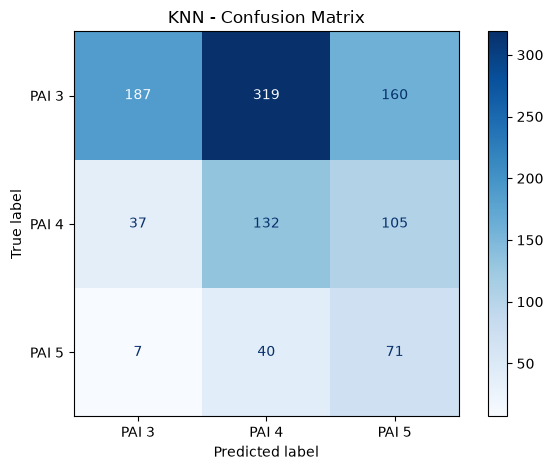

In [21]:
from sklearn.neighbors import KNeighborsClassifier

#Create KNN model with feature scaling
model_knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(
        n_neighbors=5,
        weights="distance"
    )
)

#Train the KNN model
model_knn.fit(X_train, y_train)

#Predict lesion classes using validation data
y_pred_knn = model_knn.predict(X_val)

#Display classification metrics
print("KNN - Validation Results")
print(classification_report(y_val, y_pred_knn, zero_division=0))

#Display confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_knn,
    labels=CLASSES,
    display_labels=["PAI 3", "PAI 4", "PAI 5"],
    cmap="Blues"
)

plt.title("KNN - Confusion Matrix")
plt.tight_layout()
plt.show()


## KNN Hyperparameter Experiment

Compare different values of k using validation data.


    k  Accuracy  Macro F1
0   1  0.337429  0.323697
1   3  0.351607  0.342927
2   5  0.368620  0.358273
3   7  0.379017  0.373470
4   9  0.366730  0.364689
5  15  0.371456  0.370370
6  21  0.379017  0.379470


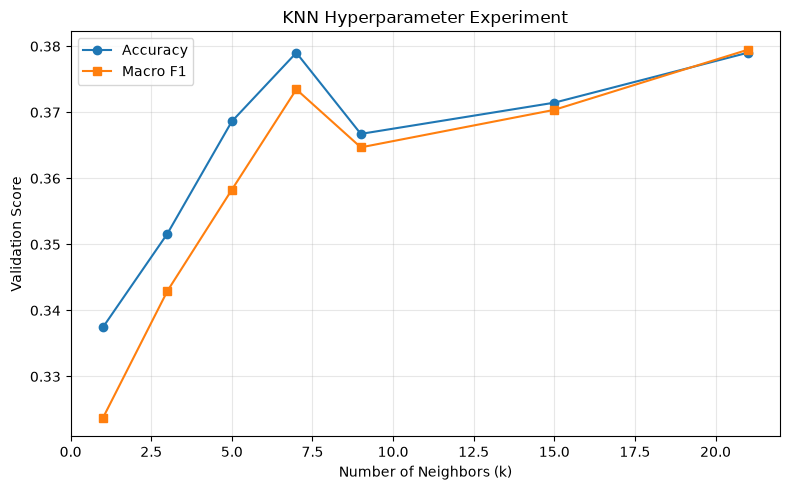

In [23]:
from sklearn.metrics import accuracy_score, f1_score

#Define the number of neighbors to evaluate
k_values = [1, 3, 5, 7, 9, 15, 21]

#Store validation results
knn_results = []

for k in k_values:

    #Create a KNN model with the current k value
    knn = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(
            n_neighbors=k,
            weights="distance"
        )
    )

    #Train the model
    knn.fit(X_train, y_train)

    #Predict validation classes
    predictions = knn.predict(X_val)

    #Calculate performance metrics
    accuracy = accuracy_score(y_val, predictions)
    macro_f1 = f1_score(y_val, predictions, average="macro")

    knn_results.append({
        "k": k,
        "Accuracy": accuracy,
        "Macro F1": macro_f1
    })

#Convert results into a table
knn_df = pd.DataFrame(knn_results)

print(knn_df)

#Plot the effect of the number of neighbors
plt.figure(figsize=(8, 5))

plt.plot(
    knn_df["k"],
    knn_df["Accuracy"],
    marker="o",
    label="Accuracy"
)

plt.plot(
    knn_df["k"],
    knn_df["Macro F1"],
    marker="s",
    label="Macro F1"
)

plt.title("KNN Hyperparameter Experiment")
plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Validation Score")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Save Best KNN

Select the configuration with the highest validation Macro F1.


In [24]:
#Select the best k using validation Macro F1
best_k = int(knn_df.loc[knn_df["Macro F1"].idxmax(), "k"])

#Train the final KNN configuration
model_knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(
        n_neighbors=best_k,
        weights="distance"
    )
)

model_knn.fit(X_train, y_train)

#Calculate validation predictions
y_pred_knn = model_knn.predict(X_val)

#Save the trained model
joblib.dump(model_knn, MODELS_DIR / "knn_model.pkl")

#Update model comparison results
knn_accuracy = accuracy_score(y_val, y_pred_knn)
knn_f1 = f1_score(y_val, y_pred_knn, average="macro")

results = pd.read_csv(RESULTS_DIR / "traditional_ml_results.csv")

#Remove previous KNN results
results = results[results["Model"] != "KNN"].copy()

#Add optimized KNN results
results = pd.concat([results, pd.DataFrame([["KNN", knn_accuracy, knn_f1]], columns=results.columns)], ignore_index=True)

#Save the updated table
results.to_csv(
    RESULTS_DIR / "traditional_ml_results.csv",
    index=False
)

print("Best k:", best_k)
print(results)


Best k: 21
                 Model  Accuracy  Macro F1
0  Logistic Regression  0.714556  0.653414
1                  SVM  0.759924  0.703932
2                  KNN  0.379017  0.379470


## Random Forest

Train and evaluate the ensemble model.


Random Forest - Validation Results
              precision    recall  f1-score   support

           3       0.80      0.89      0.85       666
           4       0.52      0.43      0.47       274
           5       0.77      0.57      0.65       118

    accuracy                           0.74      1058
   macro avg       0.70      0.63      0.66      1058
weighted avg       0.73      0.74      0.73      1058



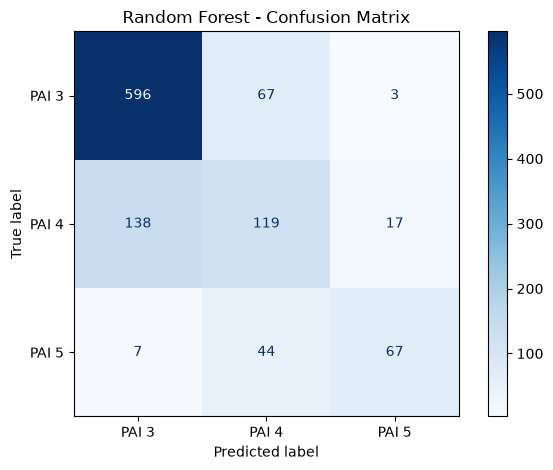

In [25]:
from sklearn.ensemble import RandomForestClassifier

#Create the Random Forest model
model_rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=None,
    class_weight="balanced",
    random_state=42,
    n_jobs=2
)

#Train the model
model_rf.fit(X_train, y_train)

#Predict validation classes
y_pred_rf = model_rf.predict(X_val)

#Display classification metrics
print("Random Forest - Validation Results")
print(classification_report(y_val, y_pred_rf, zero_division=0))

#Display confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_rf,
    labels=CLASSES,
    display_labels=["PAI 3", "PAI 4", "PAI 5"],
    cmap="Blues"
)

plt.title("Random Forest - Confusion Matrix")
plt.tight_layout()
plt.show()


## Save and Compare Models

Export the final validation comparison and figure.


Traditional ML Model Comparison
              Model  Accuracy  Macro F1
                SVM  0.759924  0.703932
      Random Forest  0.739130  0.657691
Logistic Regression  0.714556  0.653414
                KNN  0.379017  0.379470


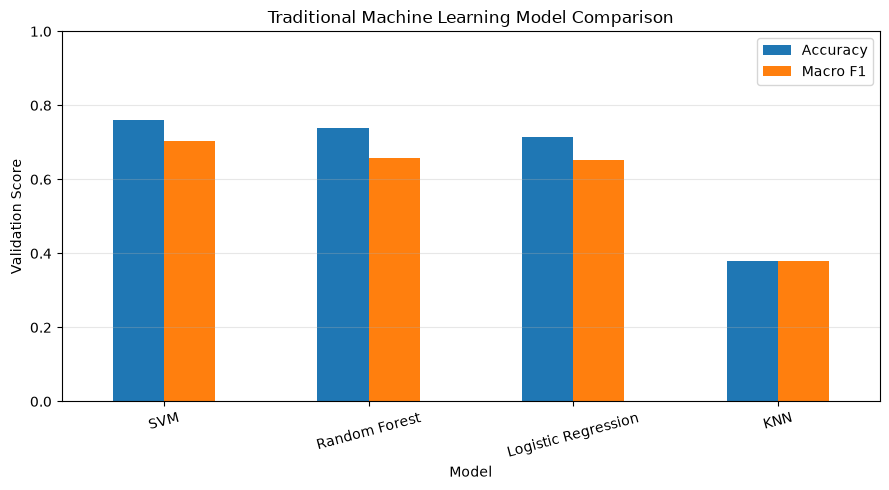

Random Forest model and comparison saved


In [27]:
#Save the trained Random Forest model
joblib.dump(model_rf, MODELS_DIR / "random_forest.pkl")

#Calculate Random Forest validation metrics
rf_accuracy = accuracy_score(y_val, y_pred_rf)
rf_f1 = f1_score(y_val, y_pred_rf, average="macro")

#Load previous model results
results_path = RESULTS_DIR / "traditional_ml_results.csv"
results = pd.read_csv(results_path)

#Remove previous Random Forest results to avoid duplicates
results = results[results["Model"] != "Random Forest"]

#Add the new model results
new_result = pd.DataFrame([{
    "Model": "Random Forest",
    "Accuracy": rf_accuracy,
    "Macro F1": rf_f1
}])

results = pd.concat([results, new_result], ignore_index=True)

#Sort models by Macro F1
results = results.sort_values("Macro F1", ascending=False)

#Save the comparison table
results.to_csv(results_path, index=False)

print("Traditional ML Model Comparison")
print(results.to_string(index=False))

#Plot model performance
ax = results.plot(
    x="Model",
    y=["Accuracy", "Macro F1"],
    kind="bar",
    figsize=(9, 5),
    rot=15
)

plt.title("Traditional Machine Learning Model Comparison")
plt.ylabel("Validation Score")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

#Save the figure for the final report
plt.savefig(
    RESULTS_DIR / "traditional_ml_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Random Forest model and comparison saved")


In [2]:
#CHECK SAVED ML MODELS

from pathlib import Path

PROJECT_DIR = Path(r"C:\ML_Course\Dental_Lesion_Detection")
MODELS_DIR = PROJECT_DIR / "models"

for model_path in sorted(MODELS_DIR.glob("*.pkl")):
    print("FOUND:", model_path.name)

FOUND: knn_model.pkl
FOUND: logistic_regression.pkl
FOUND: random_forest.pkl
FOUND: svm_model.pkl


## Traditional Machine Learning - Final Test Evaluation

In [3]:

#INSPECT SAVED ML MODELS

import joblib

#Define model files
model_files = {
    "Logistic Regression": "logistic_regression.pkl",
    "SVM": "svm_model.pkl",
    "KNN": "knn_model.pkl",
    "Random Forest": "random_forest.pkl"
}

ml_models = {}

#Load and inspect each model
for model_name, filename in model_files.items():

    model = joblib.load(MODELS_DIR / filename)
    ml_models[model_name] = model

    print(f"\nMODEL: {model_name}")
    print("Type:", type(model).__name__)
    print("Input features:", getattr(model, "n_features_in_", None))
    print("Classes:", getattr(model, "classes_", None))

    #Check preprocessing pipeline
    if hasattr(model, "named_steps"):
        print("Pipeline:", list(model.named_steps.keys()))
    else:
        print("No integrated pipeline")




MODEL: Logistic Regression
Type: Pipeline
Input features: 1777
Classes: [3 4 5]
Pipeline: ['standardscaler', 'logisticregression']

MODEL: SVM
Type: Pipeline
Input features: 1777
Classes: [3 4 5]
Pipeline: ['standardscaler', 'svc']

MODEL: KNN
Type: Pipeline
Input features: 1777
Classes: [3 4 5]
Pipeline: ['standardscaler', 'kneighborsclassifier']

MODEL: Random Forest
Type: RandomForestClassifier
Input features: 1777
Classes: [3 4 5]
No integrated pipeline


In [6]:

#CHECK AVAILABLE FEATURE FUNCTIONS

for name, obj in list(globals().items()):

    if callable(obj) and "feature" in name.lower():
        print("FOUND FUNCTION:", name)

#Check available scalers
for name in list(globals()):

    if "scaler" in name.lower():
        print("FOUND SCALER:", name)


In [10]:

#RECOVER ORIGINAL FEATURE EXTRACTION CODE

import json
from pathlib import Path

#Set correct notebook path
notebook_path = PROJECT_DIR / "notebooks" / "04_Traditional_ML_Formatted.ipynb"

#Read notebook
with open(notebook_path, "r", encoding="utf-8") as file:
    notebook = json.load(file)

#Find original feature extraction code
for i, cell in enumerate(notebook["cells"]):

    if cell["cell_type"] == "code":

        source = "".join(cell["source"])

        if "hog(" in source or "local_binary_pattern(" in source:
            print(f"\nCELL {i + 1}")
            print("-" * 60)
            print(source)



CELL 4
------------------------------------------------------------
#Extract numerical features from one image
def extract_features(image_path):

    #Load the image in grayscale
    image = Image.open(image_path).convert("L")

    #Resize to reduce processing time
    image = image.resize((64, 64))

    #Convert image to a NumPy array
    pixels = np.array(image)

    #Extract edge and shape features using HOG
    hog_features = hog(
        pixels,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2)
    )

    #Extract texture patterns using LBP
    lbp = local_binary_pattern(
        pixels, P=8, R=1, method="uniform"
    )

    #Create a normalized LBP histogram
    lbp_hist, _ = np.histogram(
        lbp, bins=10, range=(0, 10)
    )
    lbp_hist = lbp_hist.astype(float)
    lbp_hist /= lbp_hist.sum() + 1e-8

    #Calculate basic image statistics
    statistics = [
        pixels.mean(),
        pixels.std(),
        np.median(pixels)
    ]

   

In [11]:

#FEATURE EXTRACTION FOR TEST IMAGES

import numpy as np
from PIL import Image
from skimage.feature import hog, local_binary_pattern

def extract_features(image_path):

    #Load and resize grayscale image
    image = Image.open(image_path).convert("L")
    image = image.resize((64, 64))
    pixels = np.array(image)

    #Extract HOG features
    hog_features = hog(
        pixels,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2)
    )

    #Extract LBP features
    lbp = local_binary_pattern(
        pixels, P=8, R=1, method="uniform"
    )

    lbp_hist, _ = np.histogram(
        lbp, bins=10, range=(0, 10)
    )

    lbp_hist = lbp_hist.astype(float)
    lbp_hist /= lbp_hist.sum() + 1e-8

    #Calculate intensity statistics
    statistics = [
        pixels.mean(),
        pixels.std(),
        np.median(pixels)
    ]

    #Combine extracted features
    return np.concatenate([
        hog_features,
        lbp_hist,
        statistics
    ])


In [12]:

#PREPARE TEST FEATURES

TEST_DIR = PROJECT_DIR / "dataset" / "lesion_crops" / "test"

X_test = []
y_test = []

#Extract features from each class
for class_id in [3, 4, 5]:

    image_paths = sorted(
        (TEST_DIR / str(class_id)).glob("*.jpg")
    )

    print(f"Processing PAI {class_id}: {len(image_paths)} images")

    for image_path in image_paths:

        features = extract_features(image_path)

        X_test.append(features)
        y_test.append(class_id)

#Convert lists into arrays
X_test = np.array(X_test)
y_test = np.array(y_test)

print("\nTest features:", X_test.shape)
print("Test labels:", y_test.shape)

#Verify dataset dimensions
assert X_test.shape == (1000, 1777)
assert y_test.shape == (1000,)
assert np.isfinite(X_test).all()


Processing PAI 3: 628 images
Processing PAI 4: 269 images
Processing PAI 5: 103 images

Test features: (1000, 1777)
Test labels: (1000,)


In [13]:
#VERIFY RANDOM FOREST TRAINING

for i, cell in enumerate(notebook["cells"]):

    if cell["cell_type"] == "code":

        source = "".join(cell["source"])

        if "RandomForestClassifier(" in source:
            print(source)

from sklearn.ensemble import RandomForestClassifier

#Create the Random Forest model
model_rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=None,
    class_weight="balanced",
    random_state=42,
    n_jobs=2
)

#Train the model
model_rf.fit(X_train, y_train)

#Predict validation classes
y_pred_rf = model_rf.predict(X_val)

#Display classification metrics
print("Random Forest - Validation Results")
print(classification_report(y_val, y_pred_rf, zero_division=0))

#Display confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_rf,
    labels=CLASSES,
    display_labels=["PAI 3", "PAI 4", "PAI 5"],
    cmap="Blues"
)

plt.title("Random Forest - Confusion Matrix")
plt.tight_layout()
plt.show()



### Final Test Evaluation - Traditional Machine Learning


Logistic Regression - Test Results
              precision    recall  f1-score   support

           3       0.84      0.79      0.82       628
           4       0.50      0.55      0.52       269
           5       0.55      0.61      0.58       103

    accuracy                           0.71      1000
   macro avg       0.63      0.65      0.64      1000
weighted avg       0.72      0.71      0.72      1000


SVM - Test Results
              precision    recall  f1-score   support

           3       0.88      0.83      0.85       628
           4       0.55      0.67      0.60       269
           5       0.73      0.59      0.65       103

    accuracy                           0.76      1000
   macro avg       0.72      0.70      0.70      1000
weighted avg       0.78      0.76      0.77      1000


KNN - Test Results
              precision    recall  f1-score   support

           3       0.88      0.26      0.40       628
           4       0.28      0.61      0.38       269

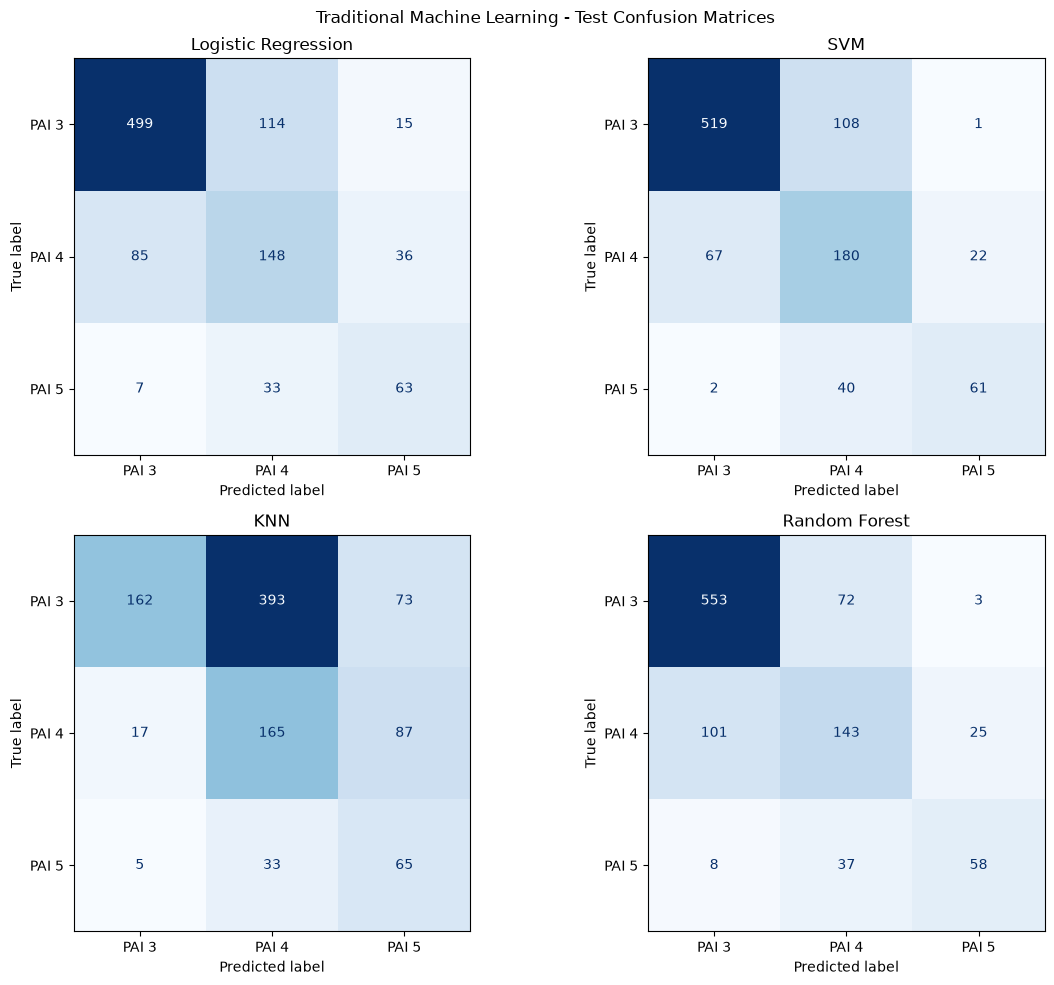

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.710,0.6329,0.6521,0.6414
1,SVM,0.760,0.7192,0.6959,0.7030
2,KNN,0.392,0.4828,0.5008,0.3930
3,Random Forest,0.754,0.6924,0.6584,0.6734


In [14]:

#FINAL TEST EVALUATION - TRADITIONAL ML

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

#Define results directory
RESULTS_DIR = PROJECT_DIR / "results"
RESULTS_DIR.mkdir(exist_ok=True)

#Store evaluation results
test_results = []

#Create confusion matrix figure
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

#Evaluate each trained model
for (model_name, model), ax in zip(
    ml_models.items(), axes.ravel()
):

    #Predict test classes
    y_pred = model.predict(X_test)

    #Calculate evaluation metrics
    test_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "F1-score": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        )
    })

    #Generate classification report
    print(f"\n{model_name} - Test Results")
    print(classification_report(
        y_test, y_pred, labels=[3, 4, 5],
        zero_division=0
    ))

    #Save individual classification report
    report = classification_report(
        y_test, y_pred, labels=[3, 4, 5],
        output_dict=True, zero_division=0
    )

    filename = model_name.lower().replace(" ", "_")

    pd.DataFrame(report).transpose().to_csv(
        RESULTS_DIR / f"{filename}_test_report.csv"
    )

    #Display confusion matrix
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=[3, 4, 5],
        display_labels=["PAI 3", "PAI 4", "PAI 5"],
        cmap="Blues",
        colorbar=False,
        ax=ax
    )

    ax.set_title(model_name)

#Save confusion matrices
plt.suptitle("Traditional Machine Learning - Test Confusion Matrices")
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "traditional_ml_test_confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#Create comparison table
test_results_df = pd.DataFrame(test_results)

#Save final test metrics
test_results_df.to_csv(
    RESULTS_DIR / "traditional_ml_test_comparison.csv",
    index=False
)

display(test_results_df.round(4))


In [15]:

#CHECK TRADITIONAL ML VALIDATION RESULTS

validation_path = RESULTS_DIR / "traditional_ml_results.csv"

if validation_path.exists():

    validation_results = pd.read_csv(validation_path)
    display(validation_results)

else:

    print("Validation results file not found")

    #List available CSV files
    for file in RESULTS_DIR.glob("*.csv"):
        print(file.name)


,Model,Accuracy,Macro F1
0,SVM,0.759924,0.703932
1,Random Forest,0.739130,0.657691
2,Logistic Regression,0.714556,0.653414
3,KNN,0.379017,0.379470


### Validation vs. Test Performance Comparison

In [16]:

#COMPARE VALIDATION AND TEST PERFORMANCE

#Load saved results
val_results = pd.read_csv(
    RESULTS_DIR / "traditional_ml_results.csv"
)

test_results = pd.read_csv(
    RESULTS_DIR / "traditional_ml_test_comparison.csv"
)

#Select and rename evaluation metrics
val_results = val_results[
    ["Model", "Accuracy", "Macro F1"]
].rename(columns={
    "Accuracy": "Validation Accuracy",
    "Macro F1": "Validation F1"
})

test_results = test_results[
    ["Model", "Accuracy", "F1-score"]
].rename(columns={
    "Accuracy": "Test Accuracy",
    "F1-score": "Test F1"
})

#Combine validation and test results
comparison = pd.merge(
    val_results, test_results, on="Model"
)

#Calculate performance differences
comparison["Accuracy Difference"] = (
    comparison["Test Accuracy"] -
    comparison["Validation Accuracy"]
)

comparison["F1 Difference"] = (
    comparison["Test F1"] -
    comparison["Validation F1"]
)

#Sort models by validation performance
comparison = comparison.sort_values(
    "Validation F1", ascending=False
).reset_index(drop=True)

#Save final comparison
comparison.to_csv(
    RESULTS_DIR / "traditional_ml_final_comparison.csv",
    index=False
)

display(comparison.round(4))


,Model,Validation Accuracy,Validation F1,Test Accuracy,Test F1,Accuracy Difference,F1 Difference
0,SVM,0.7599,0.7039,0.760,0.7030,0.0001,-0.0009
1,Random Forest,0.7391,0.6577,0.754,0.6734,0.0149,0.0157
2,Logistic Regression,0.7146,0.6534,0.710,0.6414,-0.0046,-0.0120
3,KNN,0.3790,0.3795,0.392,0.3930,0.0130,0.0136


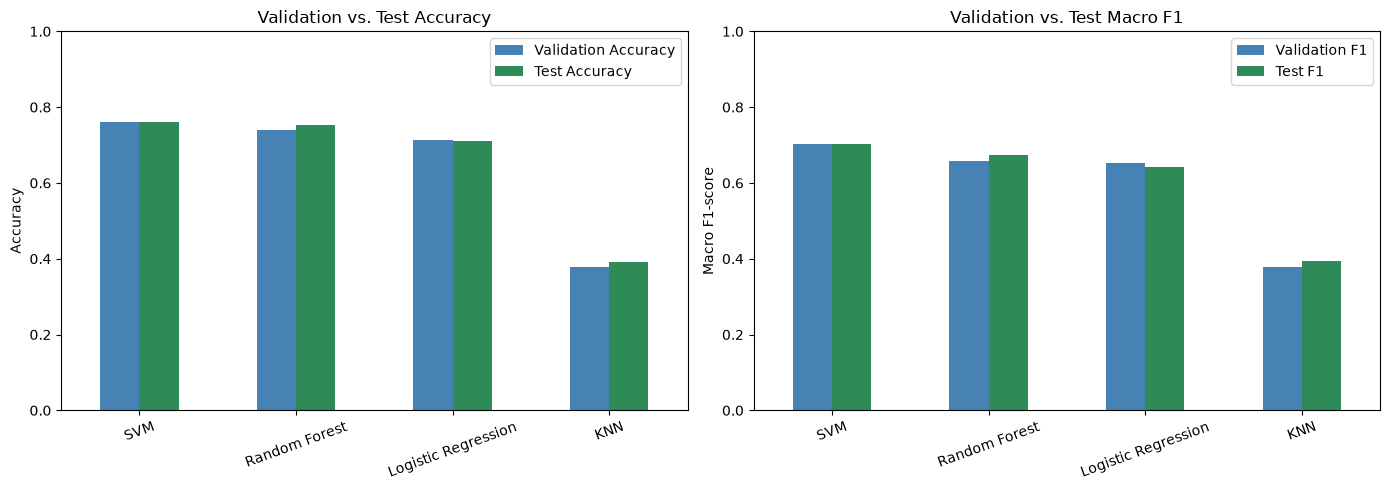

In [17]:

#PLOT VALIDATION AND TEST COMPARISON

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

#Compare accuracy
comparison.plot(
    x="Model",
    y=["Validation Accuracy", "Test Accuracy"],
    kind="bar",
    color=["steelblue", "seagreen"],
    ax=axes[0],
    rot=20
)

axes[0].set_title("Validation vs. Test Accuracy")
axes[0].set_ylabel("Accuracy")
axes[0].set_ylim(0, 1)
axes[0].set_xlabel("")

#Compare macro F1-score
comparison.plot(
    x="Model",
    y=["Validation F1", "Test F1"],
    kind="bar",
    color=["steelblue", "seagreen"],
    ax=axes[1],
    rot=20
)

axes[1].set_title("Validation vs. Test Macro F1")
axes[1].set_ylabel("Macro F1-score")
axes[1].set_ylim(0, 1)
axes[1].set_xlabel("")

plt.tight_layout()

#Save comparison figure
plt.savefig(
    RESULTS_DIR / "traditional_ml_final_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
